### 0. Import required libraries

In [27]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

### 1. Import un-sampled dataset

In [28]:
dataset_path = 'US_Accidents_March23_sampled_500k.csv'
df = pd.read_csv(dataset_path)

### 2. Exploratory Data Analysis

In [29]:
# Get a quick overview of the dataset
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     500000 non-null  str    
 1   Source                 500000 non-null  str    
 2   Severity               500000 non-null  int64  
 3   Start_Time             500000 non-null  str    
 4   End_Time               500000 non-null  str    
 5   Start_Lat              500000 non-null  float64
 6   Start_Lng              500000 non-null  float64
 7   End_Lat                279623 non-null  float64
 8   End_Lng                279623 non-null  float64
 9   Distance(mi)           500000 non-null  float64
 10  Description            499999 non-null  str    
 11  Street                 499309 non-null  str    
 12  City                   499981 non-null  str    
 13  County                 500000 non-null  str    
 14  State                  500000 non-null  str    

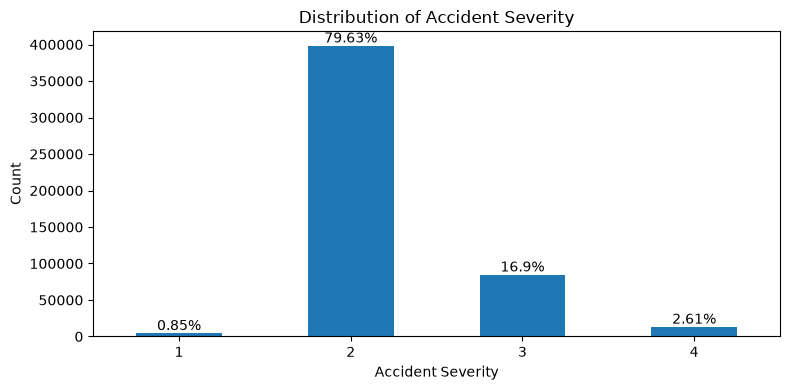

In [30]:
severity_counts = df['Severity'].value_counts().sort_index()
severity_pct = (severity_counts / len(df) * 100).round(2)
ax = severity_counts.plot(kind='bar', figsize=(8, 4), rot=0)
ax.set_xlabel('Accident Severity')
ax.set_ylabel('Count')
ax.set_title('Distribution of Accident Severity')
for i, (cnt, pct) in enumerate(zip(severity_counts, severity_pct)):
    ax.text(i, cnt, f'{pct}%', ha='center', va='bottom')
plt.tight_layout()
plt.show()

As mentioned in our proposal, severity is heavily imbalanced, with severity 2 making up roughly 80% of the records. 

In [31]:
missing = df.isna().sum()
missing = pd.DataFrame({
    'missing': missing,
    'percent': (missing / len(df) * 100).round(2)
})
missing = missing[missing['missing'] > 0].sort_values('percent', ascending=False)
missing

,missing,percent
End_Lat,220377,44.08
End_Lng,220377,44.08
Precipitation(in),142616,28.52
Wind_Chill(F),129017,25.80
Wind_Speed(mph),36987,7.40
Visibility(mi),11291,2.26
Wind_Direction,11197,2.24
Humidity(%),11130,2.23
Weather_Condition,11101,2.22
Temperature(F),10466,2.09


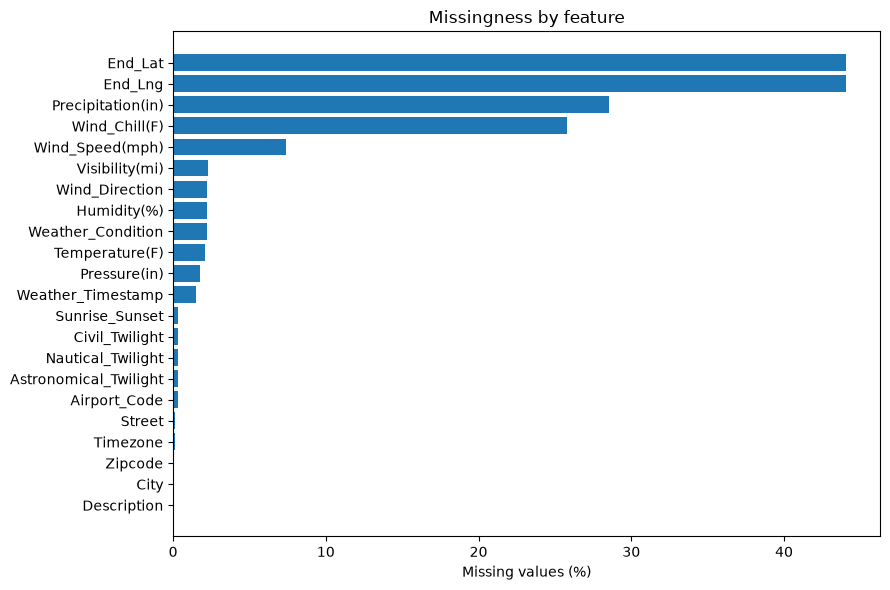

In [32]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(missing.index[::-1], missing['percent'][::-1])
ax.set_xlabel('Missing values (%)')
ax.set_title('Missingness by feature')
plt.tight_layout()
plt.show()

22 of the columns have missing values. `End_Lat` and `End_Lng` are the worst, missing in about 44% of records. `Precipitation(in)` (28.5%) and `Wind_Chill(F)` (25.8%) are the next most incomplete. The other weather features are missing in only about 2 to 7% of records. 

`Percipitation` is missing about 30% of the time, however, as you can see from the data below, missing values occured almost entirely under dry or cloudy conditions, so we believe it is safe to treat them as 0.

In [33]:
missing_precip = df['Precipitation(in)'].isna()
print("Weather conditions where precipitation is missing:")
print(df.loc[missing_precip, 'Weather_Condition'].value_counts(normalize=True).head(10).mul(100).round(1))
print("\nWeather conditions where precipitation is recorded:")
print(df.loc[~missing_precip, 'Weather_Condition'].value_counts(normalize=True).head(10).mul(100).round(1))

Weather conditions where precipitation is missing:
Weather_Condition
Clear               39.0
Overcast            16.0
Mostly Cloudy       14.9
Partly Cloudy       10.7
Scattered Clouds     9.5
Fair                 4.2
Haze                 1.4
Cloudy               0.9
Light Rain           0.7
Fog                  0.7
Name: proportion, dtype: float64

Weather conditions where precipitation is recorded:
Weather_Condition
Fair             45.1
Cloudy           14.6
Mostly Cloudy    12.8
Partly Cloudy     8.7
Light Rain        6.1
Light Snow        2.2
Fog               1.6
Rain              1.4
Overcast          1.0
Haze              0.9
Name: proportion, dtype: float64


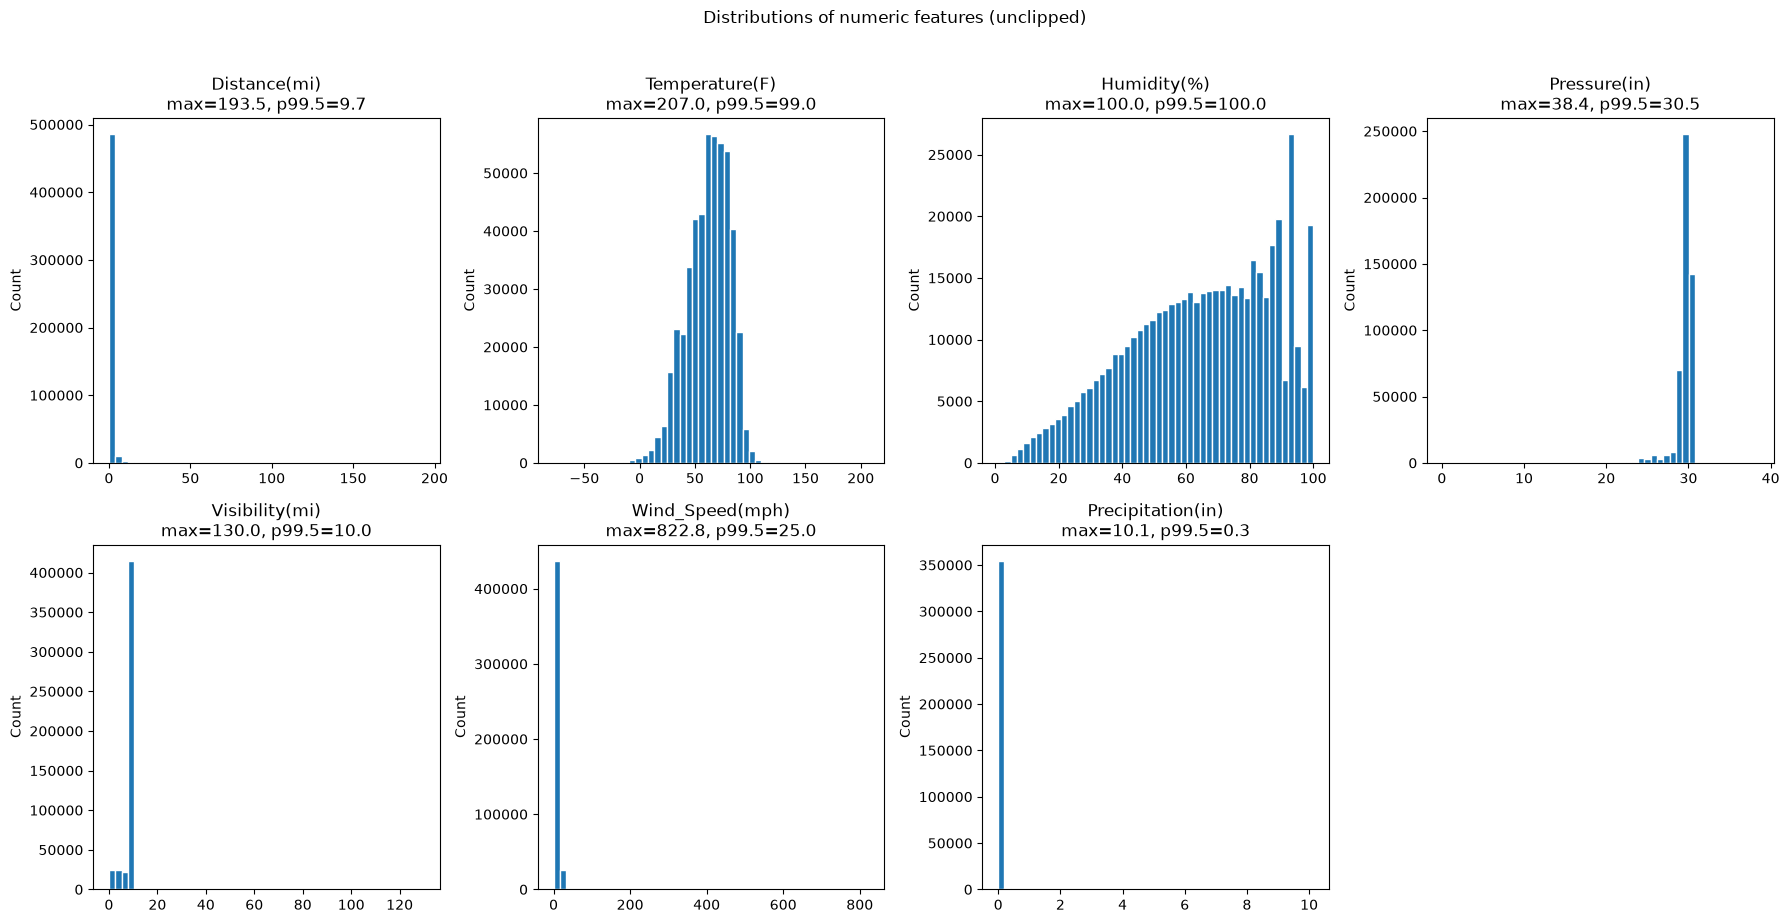

In [34]:
num_cols = ['Distance(mi)', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)',
            'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']
num_cols = [c for c in num_cols if c in df.columns]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.ravel(), num_cols):
    data = df[col].dropna()
    ax.hist(data, bins=50, edgecolor='white')
    ax.set_title(f'{col}\nmax={data.max():.1f}, p99.5={data.quantile(0.995):.1f}')
    ax.set_ylabel('Count')
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
plt.suptitle('Distributions of numeric features (unclipped)', y=1.02)
plt.tight_layout()
plt.show()

As you can see from the graphs above, much of the numerical data have outlier values, which cause the graphs to appear zoomed-out, and will later lead to issues when running our data mining algorithms. To help with this, during our data preprocessing we will remove the extreme outliers and keep only the data within the 99.5 percentile.

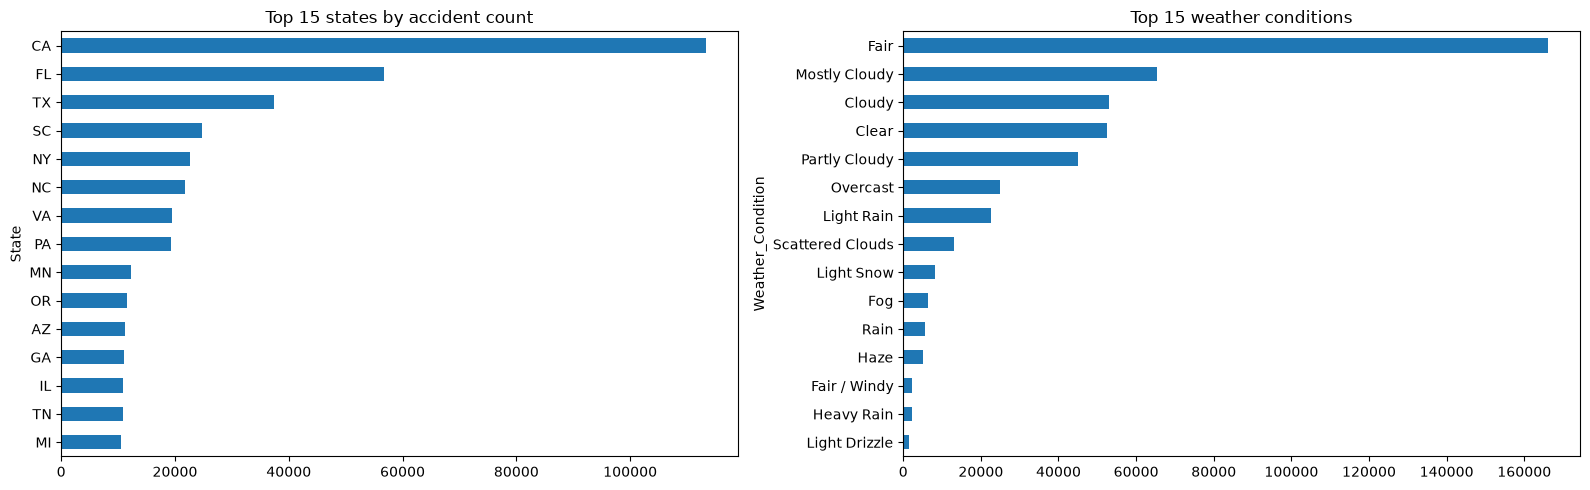

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

df['State'].value_counts().head(15).plot(kind='barh', ax=axes[0])
axes[0].invert_yaxis()
axes[0].set_title('Top 15 states by accident count')

df['Weather_Condition'].value_counts().head(15).plot(kind='barh', ax=axes[1])
axes[1].invert_yaxis()
axes[1].set_title('Top 15 weather conditions')

plt.tight_layout()
plt.show()

Understandably, the more populated states have more counts within the dataset. It is important to keep in mind that we are not predicting accident *probability* but rather accident *severity*, so the imbalance should not neccessarily bias the Severity target. However, the Severity of an accident still may vary by state regardless. 

In [36]:
# Which boolean flags are rarely True?
bool_cols = df.select_dtypes(include='bool').columns
percent_true = (df[bool_cols].mean() * 100).round(2).sort_values()
print("Percent of records where each flag is True:")
print(percent_true)

# Flags that are True in under 1% of records
rare_flags = percent_true[percent_true < 1].index

# Do those rare flags show up more often in severe accidents (severity 3 or 4)?
high = df['Severity'] >= 3
print(f"\nOverall percent of accidents with severity 3 or 4: {high.mean() * 100:.1f}%")

# For each rare flag, the percent of its True rows that are severity 3 or 4
print("\nPercent severity 3 or 4 when the flag is True:")
print(df[rare_flags].apply(lambda c: high[c].mean() * 100).round(1))

Percent of records where each flag is True:
Roundabout          0.00
Turning_Loop        0.00
Bump                0.04
Traffic_Calming     0.09
No_Exit             0.25
Give_Way            0.47
Railway             0.86
Amenity             1.24
Station             2.60
Stop                2.81
Junction            7.40
Crossing           11.25
Traffic_Signal     14.81
dtype: float64

Overall percent of accidents with severity 3 or 4: 19.5%

Percent severity 3 or 4 when the flag is True:
Roundabout          0.0
Turning_Loop        NaN
Bump               12.3
Traffic_Calming    12.7
No_Exit            12.0
Give_Way           16.8
Railway            15.3
dtype: float64


Binary flags that are true in <1% of records (e.g., Roundabout, Turning_Loop, Bump, etc.) will be dropped, as their rates of severe acidents (severity 3 or 4) were at or below the overall rate of 19.5%, so they carry little information about severity.

In [37]:
print(f"Total Unique Weather_Condition Values: {df['Weather_Condition'].nunique()}")
print((df['Weather_Condition'].value_counts(normalize=True).head(25) * 100).round(2))
shares = df['Weather_Condition'].value_counts(normalize=True).cumsum() * 100
n_99 = (shares < 99).sum() + 1
print(f"The top {n_99} weather conditions cover 99% of records with a weather value")

Total Unique Weather_Condition Values: 108
Weather_Condition
Fair                       33.96
Mostly Cloudy              13.38
Cloudy                     10.86
Clear                      10.71
Partly Cloudy               9.23
Overcast                    5.09
Light Rain                  4.65
Scattered Clouds            2.67
Light Snow                  1.68
Fog                         1.32
Rain                        1.13
Haze                        1.02
Fair / Windy                0.48
Heavy Rain                  0.44
Light Drizzle               0.30
Thunder in the Vicinity     0.24
Mostly Cloudy / Windy       0.23
Cloudy / Windy              0.22
T-Storm                     0.22
Snow                        0.20
Thunder                     0.19
Light Rain with Thunder     0.17
Smoke                       0.16
Wintry Mix                  0.16
Partly Cloudy / Windy       0.13
Name: proportion, dtype: float64
The top 27 weather conditions cover 99% of records with a weather value


As you can see, the `Weather_Condition` feature has 108 unique values, however, the top 27 conditions cover 99% of the records. Therefore, to reduce the number of category options, we can keep the top 27 conditions, and put the rest into an "other" option.

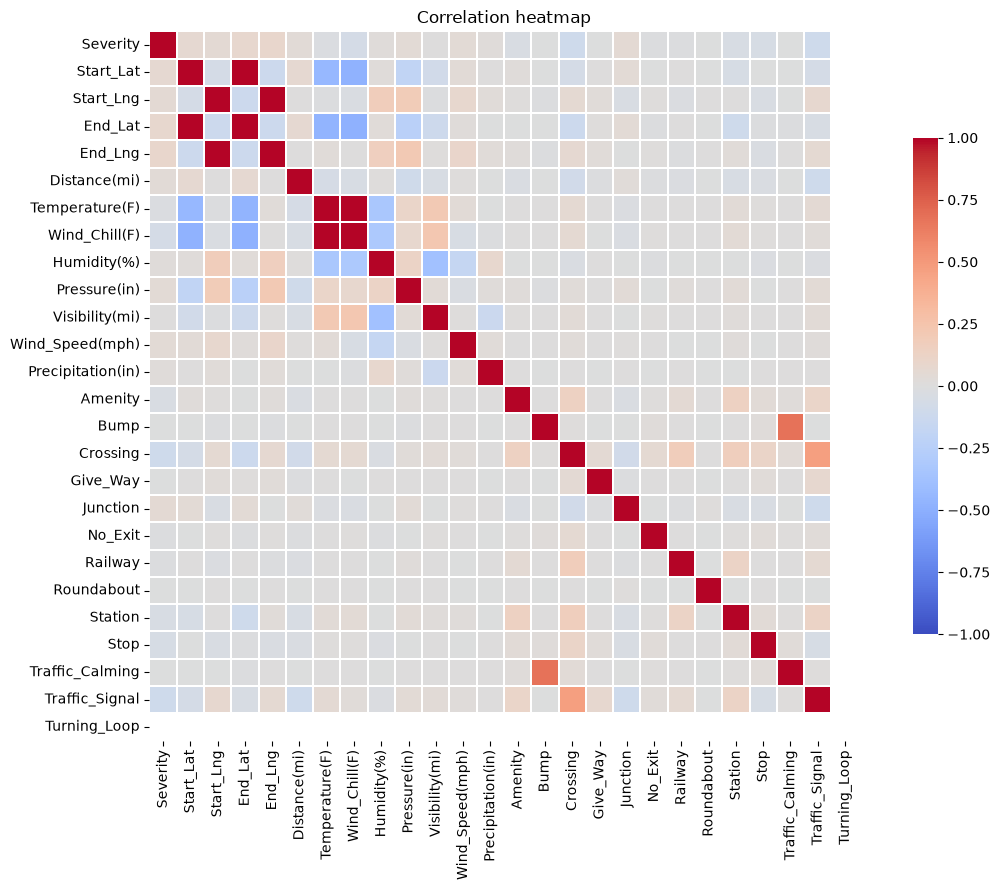

In [38]:
corr_df = pd.concat([df.select_dtypes(include='number'),
                     df.select_dtypes(include='bool').astype(int)], axis=1)
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.3, cbar_kws={'shrink': 0.7}, ax=ax)
ax.set_title('Correlation heatmap')
plt.tight_layout()
plt.show()

`Temperature(F)` and `Wind_Chill(F)` are almost perfectly correlated, as are the start and end coordinates (`Start_Lat`/`End_Lat`, `Start_Lng`/`End_Lng`). These pairs are redundant, which supports dropping `Wind_Chill(F)`, `End_Lat` and `End_Lng`.

Among the remaining features, the strongest correlations are moderate: `Crossing` with `Traffic_Signal`, and `Bump` with `Traffic_Calming`.

No feature has a strong linear correlation with `Severity`, so severity is not explained by any single factor

### 3. Data Transformation & Preprocessing

We start our data transformation by parsing the string timestamps into numerical data:

In [39]:
# Create new features

# Convert the String timestamps into pandas datetime objects
df['Start_Time'] = pd.to_datetime(df['Start_Time'], format='mixed', errors='coerce')
df['End_Time'] = pd.to_datetime(df['End_Time'], format='mixed', errors='coerce')

# Create new features using the datetime objects
df['Hour'] = df['Start_Time'].dt.hour
df['DayOfWeek'] = df['Start_Time'].dt.dayofweek
df['Month'] = df['Start_Time'].dt.month
df['Duration_min'] = (df['End_Time'] - df['Start_Time']).dt.total_seconds() / 60

As mentioned above, we will also assume that no percipitation is zero percipitation:

In [40]:
df['Precipitation(in)'] = df['Precipitation(in)'].fillna(0)

In [ ]:
# Removal of features which are not needed
to_drop = [
    'Country', # always US
    'ID', # unique per-row, so useless for training
    'Turning_Loop', # always False
    'Roundabout', # almost always False
    'Bump', # almost always False
    'Traffic_Calming', # almost always False
    'No_Exit', # almost always False, severe rate below overall
    'Give_Way', # almost always False, severe rate below overall
    'Railway', # almost always False, severe rate below overall
    'Airport_Code', # unrelated?
    'Timezone', # implied by State
    'Source', # source of the data not needed for predictions
    'Wind_Chill(F)', # redundant with Temperature, as shown in the heatmap above
    'Weather_Timestamp', # when the weather was recorded, redundant with Start_Time
    'Wind_Direction', # likely irrelevant
    
    'Civil_Twilight', # nearly identical to Sunrise_Sunset
    'Nautical_Twilight', # nearly identical to Sunrise_Sunset
    'Astronomical_Twilight', # nearly identical to Sunrise_Sunset
    
    'Zipcode', # too many unique values, location already covered by Start_Lat/Start_Lng
    'County', # too many unique values, location already covered by State and coordinates
    'End_Lat', # 44% missing and close to Start_Lat
    'End_Lng', # 44% missing and close to Start_Lng
    'Street', # too many unique values to encode usefully
    'City', # too many unique values to encode usefully
    
    'Description', # TODO: perhaps we *can* use this by making a vector?
    
    'Start_Time', # replaced by Hour, DayOfWeek, and Month
    'End_Time', # only needed to compute Duration_min
]

df = df.drop(columns=[c for c in to_drop if c in df.columns])

This leaves us with the following columns:

In [42]:
print(df.columns)

Index(['Severity', 'Start_Lat', 'Start_Lng', 'Distance(mi)', 'State',
       'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Crossing', 'Junction', 'Station', 'Stop', 'Traffic_Signal',
       'Sunrise_Sunset', 'Hour', 'DayOfWeek', 'Month', 'Duration_min'],
      dtype='str')


As reasoned for above, we will keep the top 27 options for `Weather_Condition`, and put the rest into an "other" option:

In [43]:
top_conditions = df['Weather_Condition'].value_counts().head(27).index
df['Weather_Condition'] = df['Weather_Condition'].where(
    df['Weather_Condition'].isin(top_conditions) | df['Weather_Condition'].isna(),
    'Other'
)

As mentioned above, we will clip the extreme outliers in the numeric features to their 99.5th percentile:

In [ ]:
clip_cols = ['Distance(mi)', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)',
             'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)', 'Duration_min']
for col in clip_cols:
    df[col] = df[col].clip(upper=df[col].quantile(0.995))

Finally, as we have an abundance of data, we will simply drop any records with missing data:

In [44]:
rows_before = len(df)
df = df.dropna()
print(f"Dropped {rows_before - len(df)} rows ({(rows_before - len(df)) / rows_before * 100:.1f}%), {len(df)} remaining")
print(df['Severity'].value_counts(normalize=True).sort_index().round(4) * 100)

Dropped 43158 rows (8.6%), 456842 remaining
Severity
1     0.90
2    80.38
3    16.20
4     2.51
Name: proportion, dtype: float64
